In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(1260)
transform = transforms.Compose([transforms.ToTensor()])
full_train_dataset = datasets.MNIST(
    root='./data', train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root='./data', train=False, download=True, transform=transform
)

train_size = 48000
val_size = 12000
train_dataset, val_dataset = random_split(
    full_train_dataset, [train_size, val_size]
)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train veri sayısı: {len(train_dataset)}')
print(f'Validation veri sayısı: {len(val_dataset)}')
print(f'Test veri sayısı: {len(test_dataset)}')

Train veri sayısı: 48000
Validation veri sayısı: 12000
Test veri sayısı: 10000


In [ ]:
class MLP(nn.Module):
  def __init__(self):
    super(MLP, self).__init__()
    self.flatten = nn.Flatten()

    self.katman1 = nn.Linear(28 * 28, 128)
    self.katman2 = nn.Linear(128, 64)
    self.cikis = nn.Linear(64, 10)
    self.relu = nn.ReLU()

  def forward(self, x):
    x = self.flatten(x)
    x = self.relu(self.katman1(x))
    x = self.relu(self.katman2(x))
    x = self.cikis(x)
    return x


cihaz = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_1 = MLP().to(cihaz)
print("Kullanilan cihaz:", cihaz)
print(model_1)

Kullanilan cihaz: cpu
MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (katman1): Linear(in_features=784, out_features=128, bias=True)
  (katman2): Linear(in_features=128, out_features=64, bias=True)
  (cikis): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)


In [ ]:
def model_egitim(model, train_loader, val_loader, optimizer, kayip_fonk, epoch_sayisi=20):
    train_loss_list = []
    val_loss_list = []
    train_acc_list = []
    val_acc_list = []

    baslangic = time.time()

    for epoch in range(epoch_sayisi):
        model.train()
        toplam_train_loss = 0.0
        dogru_train = 0
        toplam_train = 0

        for resimler, etiketler in train_loader:
            resimler, etiketler = resimler.to(cihaz), etiketler.to(cihaz)

            optimizer.zero_grad()
            ciktilar = model(resimler)
            loss = kayip_fonk(ciktilar, etiketler)
            loss.backward()
            optimizer.step()

            toplam_train_loss += loss.item() * resimler.size(0)
            _, tahminler = torch.max(ciktilar, 1)
            dogru_train += (tahminler == etiketler).sum().item()
            toplam_train += etiketler.size(0)

        epoch_train_loss = toplam_train_loss / toplam_train
        epoch_train_acc = (dogru_train / toplam_train) * 100

        model.eval()
        toplam_val_loss = 0.0
        dogru_val = 0
        toplam_val = 0

        with torch.no_grad():
            for resimler, etiketler in val_loader:
                resimler, etiketler = resimler.to(cihaz), etiketler.to(cihaz)
                ciktilar = model(resimler)
                loss = kayip_fonk(ciktilar, etiketler)

                toplam_val_loss += loss.item() * resimler.size(0)
                _, tahminler = torch.max(ciktilar, 1)
                dogru_val += (tahminler == etiketler).sum().item()
                toplam_val += etiketler.size(0)

        epoch_val_loss = toplam_val_loss / toplam_val
        epoch_val_acc = (dogru_val / toplam_val) * 100

        train_loss_list.append(epoch_train_loss)
        val_loss_list.append(epoch_val_loss)
        train_acc_list.append(epoch_train_acc)
        val_acc_list.append(epoch_val_acc)

        print(f"Epoch {epoch+1}/{epoch_sayisi} -> Train Loss: {epoch_train_loss:.4f}, Train Acc: %{epoch_train_acc:.2f} | Val Loss: {epoch_val_loss:.4f}, Val Acc: %{epoch_val_acc:.2f}")

    gecen_sure = time.time() - baslangic
    print(f"\nToplam Egitim Suresi: {gecen_sure:.2f} saniye")

    return train_loss_list, val_loss_list, train_acc_list, val_acc_list, gecen_sure

kayip_fonksiyonu = nn.CrossEntropyLoss()
optimizer_1 = optim.Adam(model_1.parameters(), lr=0.001)

t_loss1, v_loss1, t_acc1, v_acc1, sure1 = model_egitim(
    model_1, train_loader, val_loader, optimizer_1, kayip_fonksiyonu, epoch_sayisi=20
)

Epoch 1/20 -> Train Loss: 0.0320, Train Acc: %99.02 | Val Loss: 0.0946, Val Acc: %97.56
Epoch 2/20 -> Train Loss: 0.0256, Train Acc: %99.24 | Val Loss: 0.0971, Val Acc: %97.51
Epoch 3/20 -> Train Loss: 0.0200, Train Acc: %99.42 | Val Loss: 0.0940, Val Acc: %97.61
Epoch 4/20 -> Train Loss: 0.0164, Train Acc: %99.53 | Val Loss: 0.1006, Val Acc: %97.52
Epoch 5/20 -> Train Loss: 0.0143, Train Acc: %99.59 | Val Loss: 0.1085, Val Acc: %97.60
Epoch 6/20 -> Train Loss: 0.0130, Train Acc: %99.61 | Val Loss: 0.1092, Val Acc: %97.58
Epoch 7/20 -> Train Loss: 0.0099, Train Acc: %99.72 | Val Loss: 0.1169, Val Acc: %97.53
Epoch 8/20 -> Train Loss: 0.0128, Train Acc: %99.59 | Val Loss: 0.1213, Val Acc: %97.41
Epoch 9/20 -> Train Loss: 0.0077, Train Acc: %99.77 | Val Loss: 0.1128, Val Acc: %97.49
Epoch 10/20 -> Train Loss: 0.0052, Train Acc: %99.86 | Val Loss: 0.1170, Val Acc: %97.70
Epoch 11/20 -> Train Loss: 0.0079, Train Acc: %99.76 | Val Loss: 0.1256, Val Acc: %97.46
Epoch 12/20 -> Train Loss: 0.0

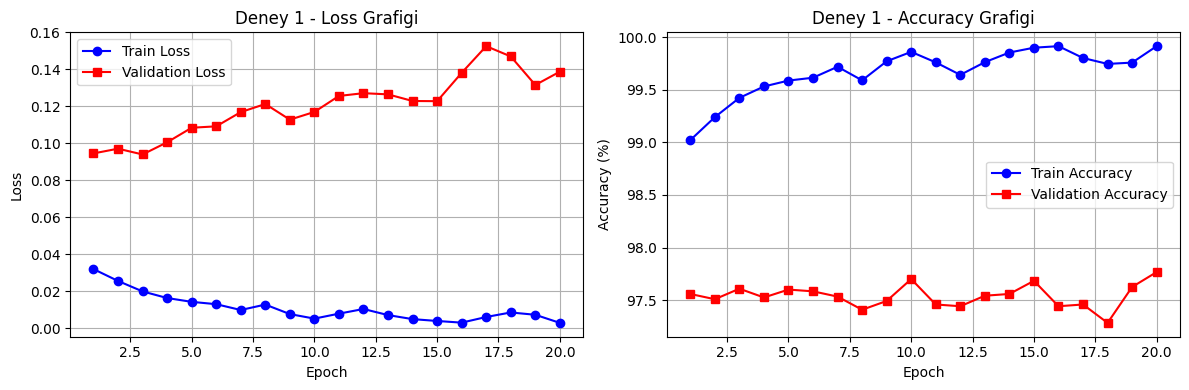

Test Accuracy: %97.73


In [12]:
epochlar = range(1, len(t_loss1) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochlar, t_loss1, "b-o", label="Train Loss")
plt.plot(epochlar, v_loss1, "r-s", label="Validation Loss")
plt.title("Deney 1 - Loss Grafigi")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochlar, t_acc1, "b-o", label="Train Accuracy")
plt.plot(epochlar, v_acc1, "r-s", label="Validation Accuracy")
plt.title("Deney 1 - Accuracy Grafigi")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

def test_et(model, test_loader):
  model.eval()
  dogru = 0
  toplam = 0
  with torch.no_grad():
    for resimler, etiketler in test_loader:
      resimler, etiketler = resimler.to(cihaz), etiketler.to(cihaz)
      ciktilar = model(resimler)
      _, tahminler = torch.max(ciktilar, 1)
      dogru += (tahminler == etiketler).sum().item()
      toplam += etiketler.size(0)
  test_acc = (dogru / toplam) * 100
  print(f"Test Accuracy: %{test_acc:.2f}")
  return test_acc


test_acc1 = test_et(model_1, test_loader)

In [13]:

class DerinMLP(nn.Module):

  def __init__(self):
    super(DerinMLP, self).__init__()
    self.flatten = nn.Flatten()

    self.katman1 = nn.Linear(28 * 28, 256)
    self.katman2 = nn.Linear(256, 128)
    self.katman3 = nn.Linear(128, 64)
    self.cikis = nn.Linear(64, 10)

    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(0.2)

  def forward(self, x):
    x = self.flatten(x)
    x = self.dropout(self.relu(self.katman1(x)))
    x = self.dropout(self.relu(self.katman2(x)))
    x = self.relu(self.katman3(x))
    x = self.cikis(x)
    return x


model_2 = DerinMLP().to(cihaz)
optimizer_2 = optim.Adam(model_2.parameters(), lr=0.001)

print("--- DENEY 2 EGITIMI ---")
t_loss2, v_loss2, t_acc2, v_acc2, sure2 = model_egitim(
    model_2, train_loader, val_loader, optimizer_2, kayip_fonksiyonu, epoch_sayisi=10
)
test_acc2 = test_et(model_2, test_loader)

--- DENEY 2 EGITIMI ---
Epoch 1/10 -> Train Loss: 0.4759, Train Acc: %85.53 | Val Loss: 0.1975, Val Acc: %94.41
Epoch 2/10 -> Train Loss: 0.1795, Train Acc: %94.66 | Val Loss: 0.1278, Val Acc: %96.28
Epoch 3/10 -> Train Loss: 0.1294, Train Acc: %96.09 | Val Loss: 0.1076, Val Acc: %96.74
Epoch 4/10 -> Train Loss: 0.0988, Train Acc: %97.03 | Val Loss: 0.0976, Val Acc: %97.15
Epoch 5/10 -> Train Loss: 0.0823, Train Acc: %97.46 | Val Loss: 0.0854, Val Acc: %97.58
Epoch 6/10 -> Train Loss: 0.0671, Train Acc: %97.86 | Val Loss: 0.0841, Val Acc: %97.72
Epoch 7/10 -> Train Loss: 0.0590, Train Acc: %98.14 | Val Loss: 0.0795, Val Acc: %97.82
Epoch 8/10 -> Train Loss: 0.0530, Train Acc: %98.32 | Val Loss: 0.0772, Val Acc: %97.87
Epoch 9/10 -> Train Loss: 0.0463, Train Acc: %98.49 | Val Loss: 0.0812, Val Acc: %97.82
Epoch 10/10 -> Train Loss: 0.0414, Train Acc: %98.69 | Val Loss: 0.0829, Val Acc: %97.83

Toplam Egitim Suresi: 103.13 saniye
Test Accuracy: %97.85


In [15]:
model_3 = MLP().to(cihaz)
optimizer_3 = optim.SGD(model_3.parameters(), lr=0.01)

print("--- DENEY 3 EGITIMI ---")
t_loss3, v_loss3, t_acc3, v_acc3, sure3 = model_egitim(
    model_3, train_loader, val_loader, optimizer_3, kayip_fonksiyonu, epoch_sayisi=10
)
test_acc3 = test_et(model_3, test_loader)

--- DENEY 3 EGITIMI ---
Epoch 1/10 -> Train Loss: 2.2361, Train Acc: %24.46 | Val Loss: 2.1153, Val Acc: %53.40
Epoch 2/10 -> Train Loss: 1.7061, Train Acc: %64.51 | Val Loss: 1.1982, Val Acc: %75.73
Epoch 3/10 -> Train Loss: 0.8592, Train Acc: %80.78 | Val Loss: 0.6591, Val Acc: %83.46
Epoch 4/10 -> Train Loss: 0.5681, Train Acc: %85.08 | Val Loss: 0.5107, Val Acc: %85.84
Epoch 5/10 -> Train Loss: 0.4714, Train Acc: %86.94 | Val Loss: 0.4452, Val Acc: %87.86
Epoch 6/10 -> Train Loss: 0.4229, Train Acc: %88.16 | Val Loss: 0.4079, Val Acc: %88.77
Epoch 7/10 -> Train Loss: 0.3922, Train Acc: %88.85 | Val Loss: 0.3824, Val Acc: %89.38
Epoch 8/10 -> Train Loss: 0.3708, Train Acc: %89.45 | Val Loss: 0.3625, Val Acc: %89.92
Epoch 9/10 -> Train Loss: 0.3539, Train Acc: %89.79 | Val Loss: 0.3480, Val Acc: %90.30
Epoch 10/10 -> Train Loss: 0.3403, Train Acc: %90.20 | Val Loss: 0.3360, Val Acc: %90.69

Toplam Egitim Suresi: 80.18 saniye
Test Accuracy: %90.56


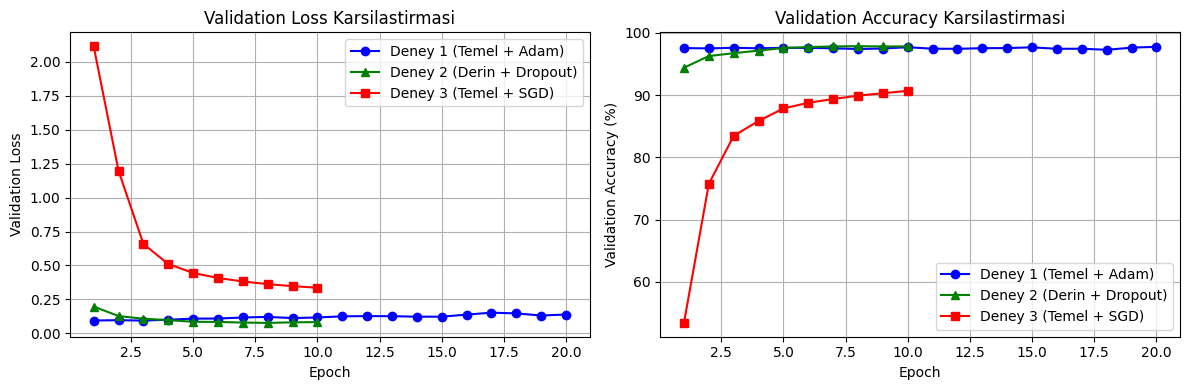

Deney                     | Train Acc  | Val Acc    | Test Acc   | Sure (sn) 
---------------------------------------------------------------------------
Deney 1 (Temel - Adam)    | %99.91     | %97.77     | %97.73     | 169.68    
Deney 2 (Derin+Dropout)   | %98.69     | %97.83     | %97.85     | 103.13    
Deney 3 (Temel - SGD)     | %90.20     | %90.69     | %90.56     | 80.18     


In [17]:
epochlar_1 = range(1, len(v_loss1) + 1)
epochlar_2 = range(1, len(v_loss2) + 1)
epochlar_3 = range(1, len(v_loss3) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochlar_1, v_loss1, "b-o", label="Deney 1 (Temel + Adam)")
plt.plot(epochlar_2, v_loss2, "g-^", label="Deney 2 (Derin + Dropout)")
plt.plot(epochlar_3, v_loss3, "r-s", label="Deney 3 (Temel + SGD)")
plt.title("Validation Loss Karsilastirmasi")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochlar_1, v_acc1, "b-o", label="Deney 1 (Temel + Adam)")
plt.plot(epochlar_2, v_acc2, "g-^", label="Deney 2 (Derin + Dropout)")
plt.plot(epochlar_3, v_acc3, "r-s", label="Deney 3 (Temel + SGD)")
plt.title("Validation Accuracy Karsilastirmasi")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("=" * 75)
print(
    f"{'Deney':<25} | {'Train Acc':<10} | {'Val Acc':<10} | {'Test Acc':<10} |"
    f" {'Sure (sn)':<10}"
)
print("-" * 75)
print(
    f"{'Deney 1 (Temel - Adam)':<25} | %{t_acc1[-1]:<9.2f} |"
    f" %{v_acc1[-1]:<9.2f} | %{test_acc1:<9.2f} | {sure1:<10.2f}"
)
print(
    f"{'Deney 2 (Derin+Dropout)':<25} | %{t_acc2[-1]:<9.2f} |"
    f" %{v_acc2[-1]:<9.2f} | %{test_acc2:<9.2f} | {sure2:<10.2f}"
)
print(
    f"{'Deney 3 (Temel - SGD)':<25} | %{t_acc3[-1]:<9.2f} |"
    f" %{v_acc3[-1]:<9.2f} | %{test_acc3:<9.2f} | {sure3:<10.2f}"
)
print("=" * 75)

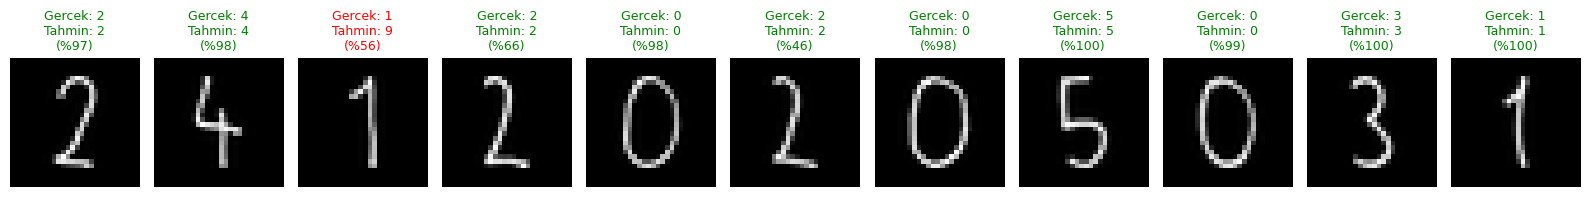


Ogrenci Numarasi Tahmin Basarisi: 11 rakamdan 10 tanesi dogru (%90.91)


In [18]:
import os
from PIL import Image, ImageOps

ogrenci_no = [2, 4, 1, 2, 0, 2, 0, 5, 0, 3, 1]
dosya_uzantisi = ".jpeg"


def resmi_mnist_formatina_cevir(dosya_yolu):
  img = Image.open(dosya_yolu).convert("L")
  img = ImageOps.invert(img)
  img_np = np.array(img).astype(np.float32)
  img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-5) * 255.0
  img_np[img_np < 100] = 0

  dolu_pikseller = np.argwhere(img_np > 0)
  if len(dolu_pikseller) > 0:
    y0, x0 = dolu_pikseller.min(axis=0)
    y1, x1 = dolu_pikseller.max(axis=0)
    kutu = img_np[y0 : y1 + 1, x0 : x1 + 1]

    h, w = kutu.shape
    kenar = max(h, w)
    kare = np.zeros((kenar, kenar), dtype=np.uint8)
    y_bas = (kenar - h) // 2
    x_bas = (kenar - w) // 2
    kare[y_bas : y_bas + h, x_bas : x_bas + w] = kutu.astype(np.uint8)

    rakam_20x20 = Image.fromarray(kare).resize(
        (20, 20), Image.Resampling.LANCZOS
    )
    mnist_resim = Image.new("L", (28, 28), 0)
    mnist_resim.paste(rakam_20x20, (4, 4))
  else:
    mnist_resim = img.resize((28, 28))

  son_np = np.array(mnist_resim, dtype=np.float32) / 255.0
  tensor_resim = torch.tensor(son_np).unsqueeze(0).unsqueeze(0)
  return mnist_resim, tensor_resim


kullanilacak_model = model_2
kullanilacak_model.eval()

dogru_sayisi = 0
plt.figure(figsize=(16, 3))

for i in range(11):
  dosya_adi = f"h{i+1}{dosya_uzantisi}"
  gercek_rakam = ogrenci_no[i]

  if not os.path.exists(dosya_adi):
    print(f"UYARI: {dosya_adi} bulunamadi! Lutfen Colab'a yukleyin.")
    continue

  islenmis_resim, girdi_tensor = resmi_mnist_formatina_cevir(dosya_adi)
  girdi_tensor = girdi_tensor.to(cihaz)

  with torch.no_grad():
    cikti = kullanilacak_model(girdi_tensor)
    olasiliklar = torch.softmax(cikti, dim=1)
    guven, tahmin = torch.max(olasiliklar, 1)
    tahmin_rakam = tahmin.item()
    guven_yuzde = guven.item() * 100

  if tahmin_rakam == gercek_rakam:
    dogru_sayisi += 1
    renk = "green"
  else:
    renk = "red"

  plt.subplot(1, 11, i + 1)
  plt.imshow(islenmis_resim, cmap="gray")
  plt.title(
      f"Gercek: {gercek_rakam}\nTahmin: {tahmin_rakam}\n(%{guven_yuzde:.0f})",
      color=renk,
      fontsize=9,
  )
  plt.axis("off")

plt.tight_layout()
plt.show()

print(
    f"\nOgrenci Numarasi Tahmin Basarisi: 11 rakamdan {dogru_sayisi} tanesi"
    f" dogru (%{dogru_sayisi/11*100:.2f})"
)